In [1]:
import pandas as pd
import matplotlib.pyplot as plt

r = pd.read_csv("../modelos/knn/resumen.csv")
r["modelo"] = r["run_name"].str[3:]
p1 = r[r["pregunta"] == "p1"].set_index("modelo")
p2 = r[r["pregunta"] == "p2"].set_index("modelo")
for nombre, t in [("p1", p1), ("p2", p2)]:
    print(nombre, t.iloc[1][["periodo_entrenamiento", "periodo_prueba", "regla_prueba"]].to_dict(),
          t.iloc[0][["n_prueba", "positivos_prueba", "tasa_observada"]].to_dict())

metricas = ["k", "auc_roc", "auc_pr", "captura_decil", "precision_decil", "lift_decil", "prob_media", "tasa_observada"]
auc_k = ["auc_validacion_k25", "auc_validacion_k50", "auc_validacion_k100", "auc_validacion_k200"]
costo = ["n_entrenamiento", "positivos_entrenamiento", "n_columnas_codificadas", "tiempo_prediccion_s", "tamano_modelo_mb"]

p1 {'periodo_entrenamiento': '2022Q1-2023Q4', 'periodo_prueba': '2024Q1-2024Q4', 'regla_prueba': 'todos los créditos'} {'n_prueba': 1044262, 'positivos_prueba': 5169, 'tasa_observada': 0.004949907207195129}
p2 {'periodo_entrenamiento': '202201-202309', 'periodo_prueba': '202401-202412', 'regla_prueba': 'grupo_muestra >= 99'} {'n_prueba': 1141651, 'positivos_prueba': 447, 'tasa_observada': 0.0003915382196485616}


## Pregunta 1: aprobación

In [2]:
p1[metricas].round(5)

,k,auc_roc,auc_pr,captura_decil,precision_decil,lift_decil,prob_media,tasa_observada
modelo,,,,,,,,
referencia_puntaje,NaN,0.77556,0.01828,0.41207,0.02040,4.12069,NaN,0.00495
v1_base,200.0,0.82243,0.02444,0.46856,0.02319,4.68559,0.00518,0.00495
v2_pesos_distancia,200.0,0.82274,0.02505,0.47050,0.02329,4.70494,0.00519,0.00495
v3_proporcion_20,200.0,0.81854,0.02436,0.46605,0.02307,4.66044,0.00519,0.00495
v4_con_estado,200.0,0.82399,0.02516,0.47146,0.02334,4.71461,0.00524,0.00495
v5_formulario,200.0,0.80431,0.02151,0.44070,0.02181,4.40701,0.00542,0.00495


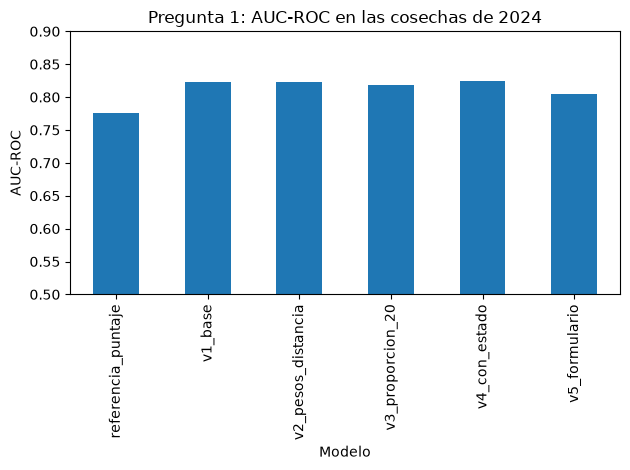

In [3]:
ax = p1["auc_roc"].plot.bar(title="Pregunta 1: AUC-ROC en las cosechas de 2024")
ax.set_xlabel("Modelo")
ax.set_ylabel("AUC-ROC")
ax.set_ylim(0.5, 0.9)
plt.tight_layout()
plt.show()

Las cinco versiones superan al puntaje solo en AUC-ROC, AUC-PR y captura del decil superior. v1, v2 y v4 quedan prácticamente empatadas y v5, que usa solo las variables del formulario de la maqueta, queda por debajo de las demás, así que las variables de la solicitud que el formulario no pide aportan al modelo. La probabilidad media corregida queda cerca de la tasa observada: la corrección por el submuestreo devuelve las probabilidades a la escala real.

modelo
v1_base               0.0029
v2_pesos_distancia    0.0028
v3_proporcion_20      0.0077
v4_con_estado         0.0026
v5_formulario         0.0066
dtype: float64


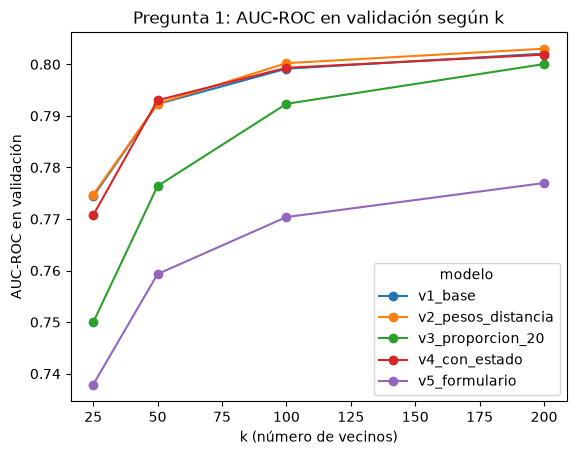

In [4]:
k1 = p1[auc_k].dropna()
k1.columns = [25, 50, 100, 200]
print((k1[200] - k1[100]).round(4))
ax = k1.T.plot(marker="o", title="Pregunta 1: AUC-ROC en validación según k")
ax.set_xlabel("k (número de vecinos)")
ax.set_ylabel("AUC-ROC en validación")
plt.show()

El AUC en validación sube con k en todas las versiones, cada vez menos. En todas se eligió k = 200, el máximo de la grilla; entre 100 y 200 la mejora de v1, v2 y v4 es de unas milésimas, así que un k mayor aportaría poco.

In [5]:
t = p1[costo].dropna().copy()
t["tiempo_prediccion_min"] = t.pop("tiempo_prediccion_s") / 60
t.round(1)

,n_entrenamiento,positivos_entrenamiento,n_columnas_codificadas,tamano_modelo_mb,tiempo_prediccion_min
modelo,,,,,
v1_base,164901.0,14991.0,29.0,3.1,18.2
v2_pesos_distancia,164901.0,14991.0,29.0,3.1,18.5
v3_proporcion_20,299985.0,14285.0,29.0,5.6,30.6
v4_con_estado,164901.0,14991.0,83.0,4.8,25.0
v5_formulario,164901.0,14991.0,68.0,3.6,23.7


El costo está en la predicción, que compara cada crédito con todo el entrenamiento. v4 agrega columnas por el estado y v3 agrega filas por la proporción 1 a 20; ambas tardan más que v1 sin una mejora que lo compense.

## Pregunta 2: alerta temprana

In [6]:
p2[metricas].round(5)

,k,auc_roc,auc_pr,captura_decil,precision_decil,lift_decil,prob_media,tasa_observada
modelo,,,,,,,,
referencia_puntaje,NaN,0.74219,0.00128,0.35347,0.00138,3.53465,NaN,0.00039
v1_base,200.0,0.86710,0.01665,0.66890,0.00262,6.68899,0.00032,0.00039
v2_pesos_distancia,200.0,0.86757,0.01731,0.67114,0.00263,6.71136,0.00032,0.00039
v3_solo_mes,200.0,0.82229,0.02284,0.64206,0.00251,6.42053,0.00034,0.00039


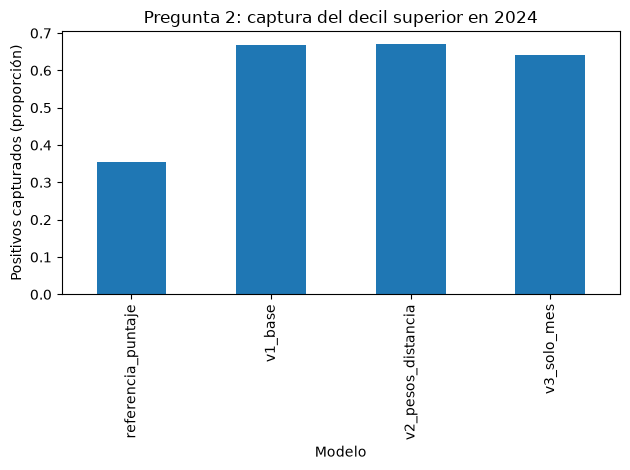

In [7]:
ax = p2["captura_decil"].plot.bar(title="Pregunta 2: captura del decil superior en 2024")
ax.set_xlabel("Modelo")
ax.set_ylabel("Positivos capturados (proporción)")
plt.tight_layout()
plt.show()

Las tres versiones superan al puntaje solo en las tres métricas, con una diferencia mucho mayor que en la pregunta 1; incluso v3, que solo usa el historial del crédito, lo supera ampliamente. v1 y v2 quedan prácticamente empatadas y concentran en el decil superior varias veces su tamaño en positivos, que es el criterio de éxito de esta pregunta. v3, sin las variables de la solicitud, ordena peor en general pero tiene el mayor AUC-PR. La probabilidad media corregida queda por debajo de la tasa observada en 2024.

modelo
v1_base               0.0098
v2_pesos_distancia    0.0096
v3_solo_mes           0.0166
dtype: float64


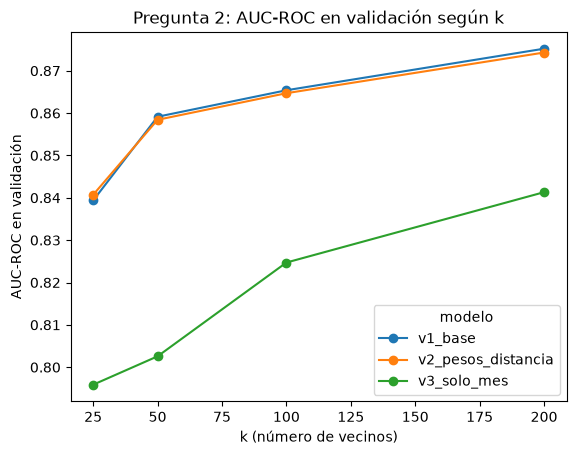

In [8]:
k2 = p2[auc_k].dropna()
k2.columns = [25, 50, 100, 200]
print((k2[200] - k2[100]).round(4))
ax = k2.T.plot(marker="o", title="Pregunta 2: AUC-ROC en validación según k")
ax.set_xlabel("k (número de vecinos)")
ax.set_ylabel("AUC-ROC en validación")
plt.show()

A diferencia de la pregunta 1, el AUC en validación todavía sube de forma apreciable entre k = 100 y k = 200, así que un k mayor podría mejorar el modelo.

In [9]:
t = p2[costo].dropna().copy()
t["tiempo_prediccion_min"] = t.pop("tiempo_prediccion_s") / 60
t.round(1)

,n_entrenamiento,positivos_entrenamiento,n_columnas_codificadas,tamano_modelo_mb,tiempo_prediccion_min
modelo,,,,,
v1_base,99990.0,9090.0,48.0,2.7,14.1
v2_pesos_distancia,99990.0,9090.0,48.0,2.7,14.1
v3_solo_mes,99990.0,9090.0,18.0,1.0,11.3


v3 es la más rápida y la más liviana porque usa menos columnas.

## Conclusiones

- Pregunta 1: se selecciona v2, la de mayor AUC-ROC entre las versiones sin el estado, con el mismo costo que la versión base.
- Pregunta 1: el estado no se incluye; su mejora es marginal y alarga la predicción.
- Pregunta 1: el formulario de la Evaluación debería pedir también las variables de la solicitud que hoy no incluye, porque sin ellas el modelo pierde capacidad de ordenar el riesgo.
- Pregunta 2: se selecciona v2, la de mayor AUC-ROC y mayor captura del decil superior.
- Pregunta 2: en la siguiente iteración conviene probar valores de k mayores a 200.